In [1]:
!cd src && make clean && make

rm -f ../build/*.o ../build/libdensity.so
clang -fPIC -fvisibility=hidden -Wall -O2 -c density_evolution.c -o ../build/density_evolution.o
clang -fPIC -fvisibility=hidden -Wall -O2 -c progress_bar.c -o ../build/progress_bar.o
clang -fPIC -fvisibility=hidden -Wall -O2 -c density_evolution_poly.c -o ../build/density_evolution_poly.o
clang -fPIC -fvisibility=hidden -Wall -O2 -c differential_evolution_poly_find.c -o ../build/differential_evolution_poly_find.o
clang -shared -o ../build/libdensity.so ../build/density_evolution.o ../build/progress_bar.o ../build/density_evolution_poly.o ../build/differential_evolution_poly_find.o


In [2]:
import ctypes
import numpy as np
import os

# Загрузка .so (или .dll на Windows)
lib_path = "build/libdensity.so"
lib = ctypes.CDLL(lib_path)

# Объявление сигнатуры функции
lib.differential_evolution_poly_find.argtypes = [
    ctypes.c_int,                         # dv_max
    ctypes.c_double,                      # r
    ctypes.c_longdouble,                  # threshold
    ctypes.c_int,                         # np
    ctypes.c_double,                      # cr
    ctypes.c_double,                      # f
    ctypes.c_int,                         # max_iters
    ctypes.POINTER(ctypes.c_longdouble),  # lambda
    ctypes.POINTER(ctypes.c_longdouble),  # rho
    ctypes.POINTER(ctypes.c_int),         # dc
    ctypes.POINTER(ctypes.c_int),         # dc_size
]
lib.differential_evolution_poly_find.restype = None

def differential_evolution_poly_find(dv_max, r, threshold, np_, cr, f_, max_iters):
    # Буферы для результатов
    lambda_buf = (ctypes.c_longdouble * dv_max)()
    rho_buf = (ctypes.c_longdouble * 100)()  # Допустим, максимум 100 степеней d_c
    dc_buf = (ctypes.c_int * 100)()
    dc_size = ctypes.c_int(0)

    # Вызов C-функции
    lib.differential_evolution_poly_find(
        ctypes.c_int(dv_max),
        ctypes.c_double(r),
        ctypes.c_longdouble(threshold),
        ctypes.c_int(np_),
        ctypes.c_double(cr),
        ctypes.c_double(f_),
        ctypes.c_int(max_iters),
        lambda_buf,
        rho_buf,
        dc_buf,
        ctypes.byref(dc_size)
    )

    # Преобразуем в словари: степень → коэффициент
    lmbd = {i + 1: float(lambda_buf[i]) for i in range(dv_max) if lambda_buf[i] > 1e-20}
    rho = {int(dc_buf[i]): float(rho_buf[i]) for i in range(dc_size.value)}

    return lmbd, rho

In [ ]:
dv_max = 5
r = 0.5
threshold = 1e-15
n = 50
cr = 0.9
f = 0.8
max_iters = 50

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters)

print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [#######                                           ] 14%

In [1]:
from matplotlib import pyplot as plt
from tqdm import tqdm
from itertools import product
import ctypes
import numpy as np
from decoding_limit import decoding_limit

lib.density_evolution_grid_irregular.argtypes = [
    ctypes.POINTER(ctypes.c_longdouble),  # p0_vals
    ctypes.c_int,                         # n_p0
    ctypes.POINTER(ctypes.c_longdouble),  # p_minus_vals
    ctypes.c_int,                         # n_p_minus
    ctypes.POINTER(ctypes.c_int),         # dv
    ctypes.POINTER(ctypes.c_int),         # dc
    ctypes.POINTER(ctypes.c_longdouble),  # lambda
    ctypes.POINTER(ctypes.c_longdouble),  # rho
    ctypes.c_int,                         # dv_size
    ctypes.c_int,                         # dc_size
    ctypes.c_int,                         # num_iters
    ctypes.c_longdouble,                  # threshold
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS")   # results
]

def density_evolution_grid_irregular(p0_vals, p_minus_vals, lmbd: dict, rho: dict, num_iters: int, threshold: float):
    """
    Обёртка над C-функцией density_evolution_grid_irregular.

    Аргументы:
        p0_vals (array-like): значения p0, по которым строится сетка
        p_minus_vals (array-like): значения p_minus, по которым строится сетка
        lmbd (dict): распределение степеней переменных, например {2: 0.5, 3: 0.5}
        rho (dict): распределение степеней проверочных узлов, например {6: 1.0}
        num_iters (int): количество итераций
        threshold (float): порог, ниже которого значение считается исчезнувшим

    Возвращает:
        results (np.ndarray): массив размера (len(p0_vals), len(p_minus_vals)), сглаженная сетка результатов
    """
    # Преобразуем входы
    p0_vals = np.asarray(p0_vals, dtype=np.longdouble)
    p_minus_vals = np.asarray(p_minus_vals, dtype=np.longdouble)
    n_p0 = len(p0_vals)
    n_p_minus = len(p_minus_vals)

    # Преобразуем словари степеней
    dv_keys = sorted(lmbd.keys())
    dc_keys = sorted(rho.keys())

    dv = (ctypes.c_int * len(dv_keys))(*dv_keys)
    dc = (ctypes.c_int * len(dc_keys))(*dc_keys)
    
    lambda_arr = (ctypes.c_longdouble * len(dv_keys))(*[lmbd[k] for k in dv_keys])
    rho_arr = (ctypes.c_longdouble * len(dc_keys))(*[rho[k] for k in dc_keys])

    # Указатели на p0 и p_minus
    p0_ptr = p0_vals.ctypes.data_as(ctypes.POINTER(ctypes.c_longdouble))
    p_minus_ptr = p_minus_vals.ctypes.data_as(ctypes.POINTER(ctypes.c_longdouble))

    # Выходной массив результатов
    results = np.full(len(p0_vals), -1, dtype=np.float64)

    # Вызов функции
    lib.density_evolution_grid_irregular(
        p0_ptr,
        ctypes.c_int(n_p0),
        p_minus_ptr,
        ctypes.c_int(n_p_minus),
        dv,
        dc,
        lambda_arr,
        rho_arr,
        ctypes.c_int(len(dv_keys)),
        ctypes.c_int(len(dc_keys)),
        ctypes.c_int(num_iters),
        ctypes.c_longdouble(threshold),
        results
    )

    # Преобразование в 2D NumPy-массив
    return results

NameError: name 'lib' is not defined

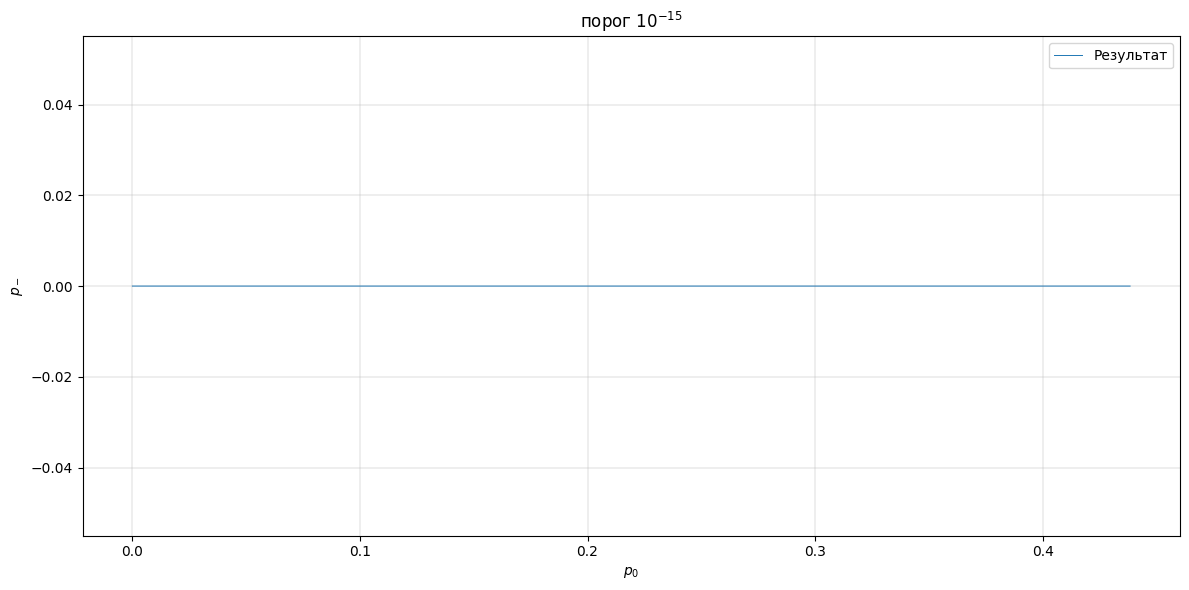

In [10]:
plt.figure(figsize=(12, 6))
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(1e-3, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)

threshold = 1e-15

not_r = 2

num_iters = 60

results = density_evolution_grid_irregular(p0_vals, p_minus_vals, lmbd, rho, num_iters, threshold)

mask = results > -1
points = np.array([p0_vals[np.argwhere(mask)].ravel(), p_minus_vals[results[mask].astype(int)].ravel()])
plt.plot(points[0, :], points[1, :], label=f'Результат', linewidth=0.7)

# for l in range(3, 4):
#     results = density_evolution_grid_irregular(p0_vals, p_minus_vals, {l:1}, {(not_r*l):1}, num_iters, threshold)

#     print(f'({l}, {l*not_r})')
#     mask = results > -1
#     points = np.array([p0_vals[np.argwhere(mask)].ravel(), p_minus_vals[results[mask].astype(int)].ravel()])
#     plt.plot(points[0, :], points[1, :], label=f'({l}, {l*not_r})', linewidth=0.7)

# plt.plot(*decoding_limit(), label="Теоретическая граница", color='black', linestyle='-.')
plt.title(f'порог $10^{{{int(np.log10(threshold))}}}$')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend()
plt.tight_layout()